some experiments with the geo and spatial data analysis 

In [1]:
# imports 

import geopandas as gpd
from shapely.geometry import Point



: 

In [ ]:
locations = {"name": ["Senate House","Russell Square"]}

geometry = [Point(-0.1300, 51.5215),Point(-0.1250, 51.5225)]

gdf = gpd.GeoDataFrame(locations,geometry=geometry,crs="EPSG:4326")

print(gdf)
print(gdf.crs)

             name                geometry
0    Senate House   POINT (-0.13 51.5215)
1  Russell Square  POINT (-0.125 51.5225)
EPSG:4326


In [ ]:
projected = gdf.to_crs("EPSG:32630")

distance = projected.geometry.iloc[0].distance(projected.geometry.iloc[1])

print(distance, "meters")

364.46566774053025 meters


In [ ]:
# create two points 
geometry = [Point(-0.1300, 51.5215) ,Point(-0.1250, 51.5225)]
locations = {'name' :['l_1' , 'l_2']}
gdf = gpd.GeoDataFrame( locations , geometry= geometry ,crs = 'EPSG:4326')
print(gdf.crs)

EPSG:4326


In [ ]:
# project the gdf to planar 
projected = gdf.to_crs('EPSG:32630')
projected

,name,geometry
0,l_1,POINT (699102.075 5711725.435)
1,l_2,POINT (699444.506 5711850.24)


In [ ]:
gdf.geometry[0].distance(gdf.geometry[1])

0.0050990195135923325

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

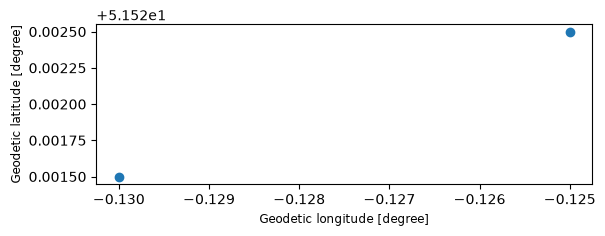

In [ ]:
gdf.plot()

In [ ]:
from shapely.geometry import LineString

#create a new line string with multiple sequences 
l = LineString([(0,0) , (3,4) ,(5,2)])

print(f'''
    length :{l.length}
    type : {l.geom_type} 
    coords : {l.coords}
    bounds : {l.bounds}
    validation : {l.is_valid}
        ''')




    length :7.82842712474619
    type : LineString 
    coords : <shapely.coords.CoordinateSequence object at 0x767d9e2760d0>
    bounds : (0.0, 0.0, 5.0, 4.0)
    validation : True
        


In [ ]:


print(l.interpolate(3)) # 3 units away from the beginning 
# this is the same as 
print(((0 + ((3/5) * 3 )) , (0 + ((3/5) * 4 )))) #starting from the beginning we can try to trace the road segment 



POINT (1.7999999999999998 2.4)
(1.7999999999999998, 2.4)


In [ ]:


point = l.interpolate(0.5 , normalized= True)
print(point)


POINT (2.348528137423857 3.131370849898476)


In [ ]:
from shapely.geometry import Point
location = Point(1.8,2.4)
distance_along_road = l.project(location)
print(distance_along_road)


3.0


In [ ]:
from shapely.geometry import Point
from shapely.ops import nearest_points

road = LineString([Point(0,0) , Point(0,10)])
location = Point(4,3)
nearest_on_road, nearest_on_gps = nearest_points(road , location)
print(nearest_on_road)
# we can even find the least distance 
road.distance(location)


POINT (0 3)


4.0

In [ ]:
road_buffer = road.buffer(30)
print(road_buffer)

POLYGON ((-30 10, -29.855541800165906 12.940514209886825, -29.423558412096913 15.852709660483859, -28.708210071966263 18.708540317633872, -27.716385975338603 21.4805029709527, -26.457637930450648 24.141902104779938, -24.94408836907636 26.667106990588067, -23.19031360088211 29.031798524909366, -21.213203435596423 31.213203435596427, -19.031798524909362 33.190313600882114, -16.66710699058806 34.94408836907637, -14.14190210477993 36.45763793045065, -11.480502970952692 37.7163859753386, -8.708540317633865 38.70821007196626, -5.852709660483846 39.42355841209691, -2.9405142098868193 39.85554180016591, 0 40, 2.940514209886823 39.85554180016591, 5.85270966048385 39.42355841209691, 8.70854031763387 38.70821007196626, 11.480502970952696 37.7163859753386, 14.141902104779934 36.457637930450645, 16.667106990588064 34.94408836907636, 19.031798524909366 33.19031360088211, 21.213203435596427 31.213203435596423, 23.19031360088211 29.031798524909362, 24.94408836907636 26.667106990588064, 26.457637930450

In [ ]:
print(road_buffer.geom_type)

Polygon


In [ ]:
road_b = LineString([(3,2), (12,5),(6,7)])
road_a = LineString([(5,3), (12,2),(4,9)])


In [ ]:
print(road_a.intersects(road_b))

True


In [ ]:
road_a.crosses(road_b)

True

In [ ]:
road_a.overlaps(road_b)

False

In [ ]:
# park.contains(location)
# location.within(park)

In [ ]:
from shapely.geometry import LineString, Point

road_a = LineString([
    (0, 0),
    (10, 0)
])

road_b = LineString([
    (5, -5),
    (5, 5)
])

intersection = road_a.intersection(road_b)

print(intersection)
print(intersection.geom_type)

POINT (5 0)
Point
